# YOLO26s 全参数微调 vs LoRA 公平对照实验

两组实验都从项目根目录的官方 `yolo26s.pt` 出发，使用相同的 train/valid/test、`seed=42` 和正式 `imgsz=768`。全参分支训练全部参数；LoRA 分支训练 39 个卷积 Adapter，并训练因 COCO 80 类切换到本项目 3 类而重新初始化的检测头。

> 这与 `yolo26s_lora_finetuning_formal.ipynb` 的增量适配实验不同。后者从已完成的全参模型出发，不能用于公平比较训练方法。

In [1]:
from pathlib import Path
import hashlib, json, sys

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'training').is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print('Project:', PROJECT_ROOT)

Project: D:\dev\projects\yolo_train


In [2]:
import torch, ultralytics
from training.train_yolo26_lora_comparison import OFFICIAL_BASE, run_comparison_lora
from training.compare_yolo26_full_vs_lora import build_report, DEFAULT_LORA_RUN

FULL_BEST = PROJECT_ROOT / 'models/trained/yolo26/formal/yolo26s_full_768_formal/weights/best.pt'
print('Python:', sys.version.split()[0])
print('Ultralytics:', ultralytics.__version__, ultralytics.__file__)
print('CUDA:', torch.cuda.is_available())
print('Official common base:', OFFICIAL_BASE)
print('Official base SHA256:', hashlib.sha256(OFFICIAL_BASE.read_bytes()).hexdigest())
print('Completed full best:', FULL_BEST)
if '.venv-yolo26' not in str(Path(ultralytics.__file__).resolve()):
    raise RuntimeError('必须选择 Python (YOLO26 Project) Kernel')
if not torch.cuda.is_available() or not OFFICIAL_BASE.is_file() or not FULL_BEST.is_file():
    raise RuntimeError('CUDA、官方共同起点或全参基线不可用')

Python: 3.13.9
Ultralytics: 8.4.55 D:\dev\projects\yolo_train\.venv-yolo26\Lib\site-packages\ultralytics\__init__.py
CUDA: True
Official common base: D:\dev\projects\yolo_train\yolo26s.pt
Official base SHA256: 646f8bc3fe0a656803d95c294f7852321748cb29d13466a1af8862e2db384a1b
Completed full best: D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\weights\best.pt


## 已通过的 3-epoch 冒烟

冒烟只验证参数冻结、新检测头梯度、Adapter、合并权重和固定 test 链路，不参加正式对比。

In [3]:
SMOKE_RUN = PROJECT_ROOT / 'models/experiments/yolo26s_full_vs_lora/lora_runs/smoke/yolo26s_lora_from_pretrained_smoke_20260719'
smoke_manifest = json.loads((SMOKE_RUN / 'lora_manifest.json').read_text(encoding='utf-8'))
smoke_manifest

{'format': 'yolo26-conv-lora-v1',
 'smoke_only': True,
 'base_model': 'D:\\dev\\projects\\yolo_train\\yolo26s.pt',
 'base_sha256': '646f8bc3fe0a656803d95c294f7852321748cb29d13466a1af8862e2db384a1b',
 'merged_best': 'D:\\dev\\projects\\yolo_train\\models\\experiments\\yolo26s_full_vs_lora\\lora_runs\\smoke\\yolo26s_lora_from_pretrained_smoke_20260719\\weights\\best.pt',
 'lora_best': 'D:\\dev\\projects\\yolo_train\\models\\experiments\\yolo26s_full_vs_lora\\lora_runs\\smoke\\yolo26s_lora_from_pretrained_smoke_20260719\\weights\\lora_best.pt',
 'adapter': 'D:\\dev\\projects\\yolo_train\\models\\experiments\\yolo26s_full_vs_lora\\lora_runs\\smoke\\yolo26s_lora_from_pretrained_smoke_20260719\\adapters\\adapter.pt',
 'config': {'rank': 8,
  'alpha': 8.0,
  'dropout': 0.05,
  'min_layer': 10,
  'max_layer': 22,
  'min_channels': 32,
  'exclude_attention': True},
 'train_head': True,
 'trainable_parameters': {'total': 10168298,
  'trainable': 1152298,
  'adapter': 218112,
  'head': 934186},
 

## 正式 LoRA 对照分支

设置 `RUN_FORMAL=True` 后运行。输出完全隔离在 `models/experiments/yolo26s_full_vs_lora/`，不会覆盖任何现有模型。

In [4]:
RUN_FORMAL = True  # 确认要启动最长 150 epochs 后手动改为 True
if RUN_FORMAL:
    lora_best = run_comparison_lora(
        smoke=False, epochs=150, imgsz=768, batch=4,
        run_name='yolo26s_lora_from_pretrained_formal',
        resume=False, export_onnx=True,
    )
    print('Formal comparison LoRA best:', lora_best)
else:
    print('未启动正式训练；将 RUN_FORMAL 改为 True 后再运行本 Cell。')

Ultralytics 8.4.55  Python-3.13.9 torch-2.13.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\dev\projects\yolo_train\data\processed\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22], half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=D:\dev\projects\yolo_train\yolo26s.pt, mom

D:\dev\runtimes\conda\envs\yolo\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset11.py:954: UserWarning: Exporting aten::index operator of advanced indexing in opset 18 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.
  return opset9.index(g, self, index)


ONNX: slimming with onnxslim 0.1.94...
ONNX: export success  1.6s, saved as 'D:\dev\projects\yolo_train\models\experiments\yolo26s_full_vs_lora\lora_runs\formal\yolo26s_lora_from_pretrained_formal\weights\best.onnx' (36.5 MB)

Export complete (1.7s)
Results saved to D:\dev\projects\yolo_train\models\experiments\yolo26s_full_vs_lora\lora_runs\formal\yolo26s_lora_from_pretrained_formal\weights\best.onnx
Predict:         yolo predict task=detect model=D:\dev\projects\yolo_train\models\experiments\yolo26s_full_vs_lora\lora_runs\formal\yolo26s_lora_from_pretrained_formal\weights\best.onnx imgsz=768 
Validate:        yolo val task=detect model=D:\dev\projects\yolo_train\models\experiments\yolo26s_full_vs_lora\lora_runs\formal\yolo26s_lora_from_pretrained_formal\weights\best.onnx imgsz=768 data=D:\dev\projects\yolo_train\data\processed\data.yaml  
Visualize:       https://netron.app
Formal comparison LoRA best: D:\dev\projects\yolo_train\models\experiments\yolo26s_full_vs_lora\lora_runs\forma

## 生成统一比较报告

正式 LoRA 完成后运行本 Cell，生成指标柱状图、训练动态曲线和包含训练参数量/耗时/模型大小的 JSON 报告。

In [5]:
if DEFAULT_LORA_RUN.is_dir() and (DEFAULT_LORA_RUN / 'lora_manifest.json').is_file():
    report_path = build_report()
    comparison = json.loads(report_path.read_text(encoding='utf-8'))
    print('Report:', report_path)
    comparison
else:
    print('正式 LoRA 对照训练尚未完成，当前不能生成最终比较报告。')

Report: D:\dev\projects\yolo_train\models\experiments\yolo26s_full_vs_lora\comparison\comparison.json


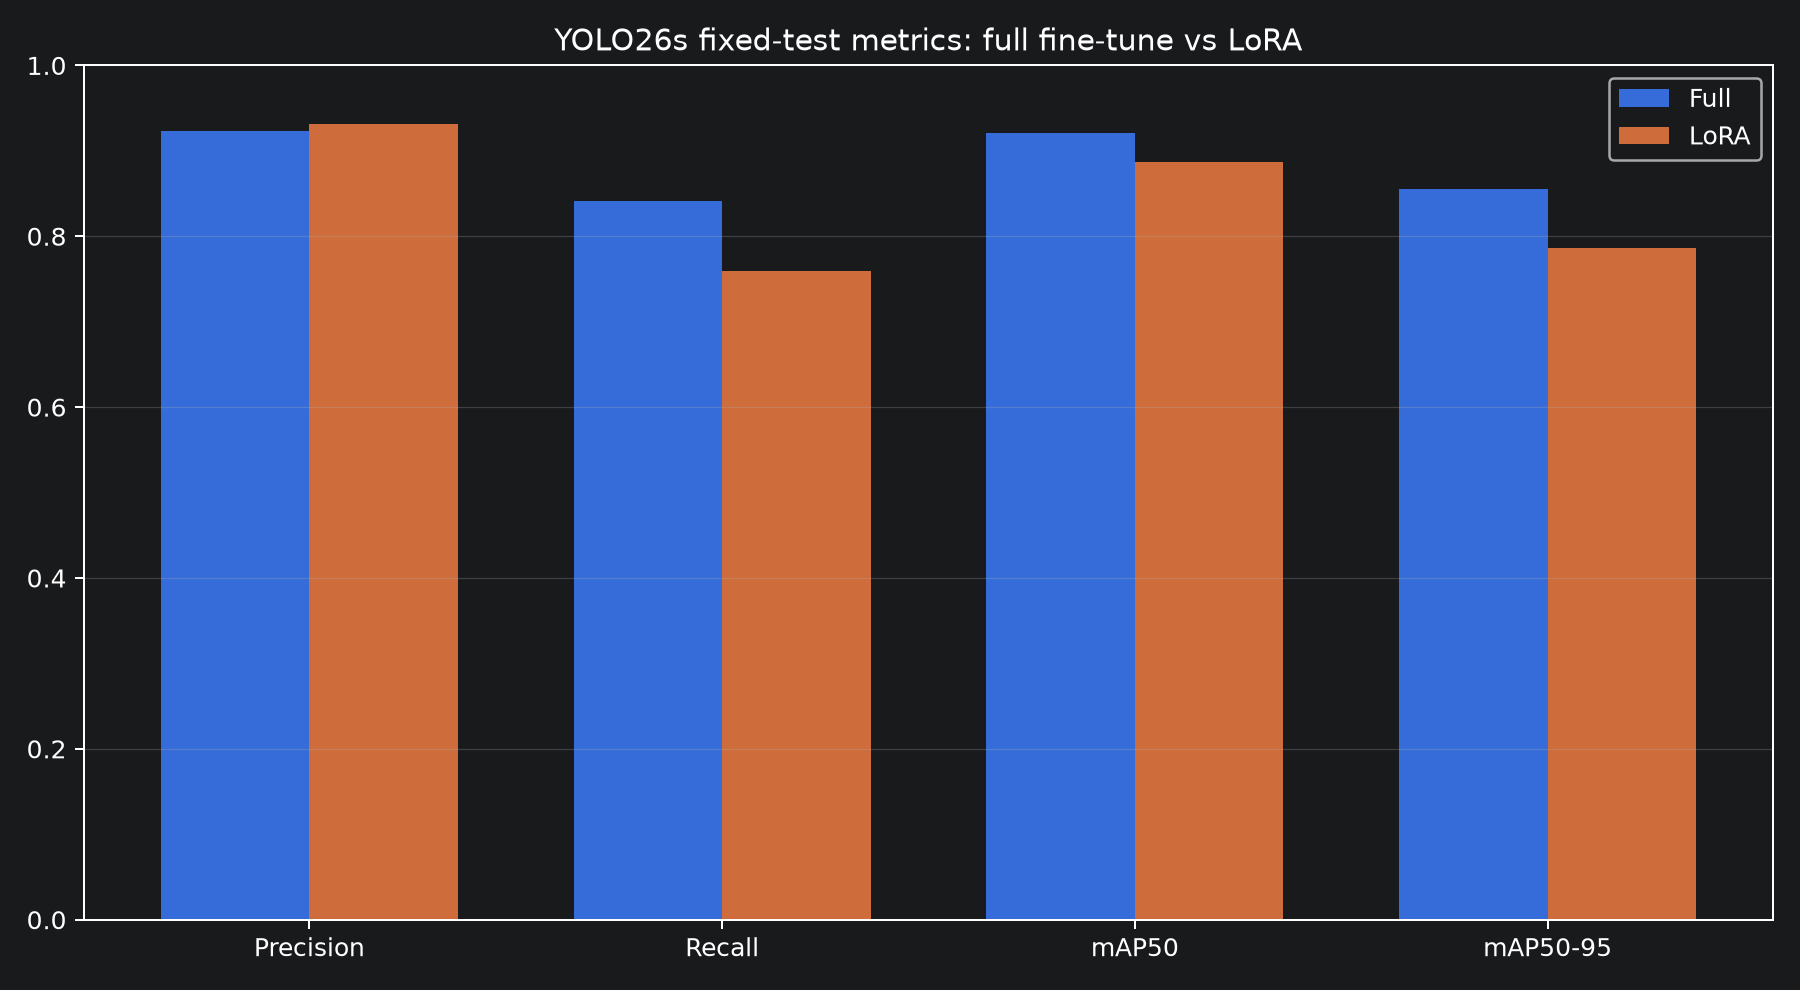

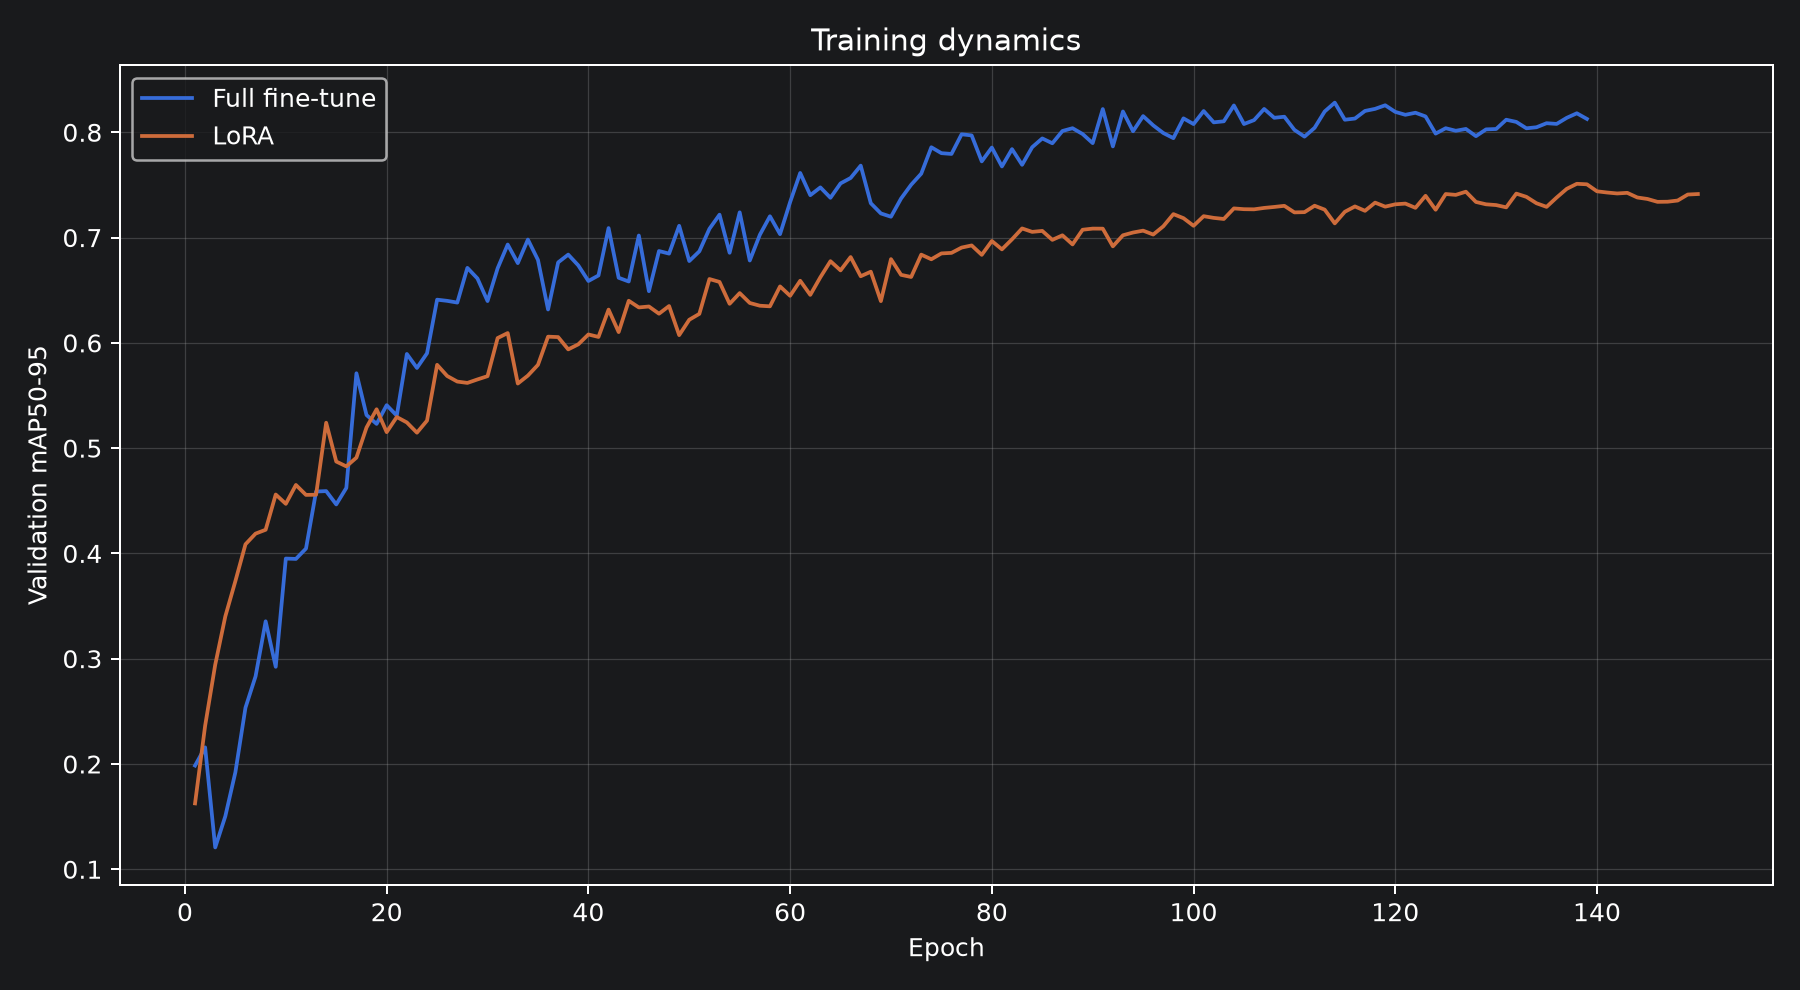

In [6]:
from IPython.display import Image, display
REPORT_DIR = PROJECT_ROOT / 'models/experiments/yolo26s_full_vs_lora/comparison'
for name in ('metrics_comparison.png', 'training_dynamics.png'):
    path = REPORT_DIR / name
    if path.is_file():
        display(Image(filename=str(path)))